In [8]:
#import and config
import os
import numpy as np
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import pandas as pd
import tensorflow as tf
import tensorflow_recommenders as tfrs

processed_path = "../dataset/processed"

retrieval_interactions = pd.read_parquet(
    os.path.join(processed_path, "retrieval_interactions.parquet")
)

movie_features = pd.read_parquet(
    os.path.join(processed_path, "movie_features.parquet")
)

user_features = pd.read_parquet(
    os.path.join(processed_path, "user_features.parquet")
)

print("Retrieval interactions:", retrieval_interactions.shape)
print("Movie features:", movie_features.shape)
print("User features:", user_features.shape)
print("TensorFlow:", tf.__version__)
print("TFRS:", tfrs.__version__)

Retrieval interactions: (575281, 3)
Movie features: (3883, 20)
User features: (6040, 4)
TensorFlow: 2.21.0
TFRS: v0.7.7


In [3]:
#prepare user and movie id vocabularies 
user_ids = retrieval_interactions["user_id"].unique().tolist()
movie_ids = movie_features["movie_id"].unique().tolist()

print("Unique user IDs:", len(user_ids))
print("Unique movie IDs:", len(movie_ids))

Unique user IDs: 6038
Unique movie IDs: 3883


In [4]:
#retrieval data into tensorflow
retrieval_data = tf.data.Dataset.from_tensor_slices({
    "user_id": retrieval_interactions["user_id"].values,
    "movie_id": retrieval_interactions["movie_id"].values
})

print("Dataset element spec:")
print(retrieval_data.element_spec)

Dataset element spec:
{'user_id': TensorSpec(shape=(), dtype=tf.string, name=None), 'movie_id': TensorSpec(shape=(), dtype=tf.string, name=None)}


In [9]:
# Per-user chronological train-test split

retrieval_sorted = retrieval_interactions.sort_values(
    ["user_id", "timestamp"]
).copy()

retrieval_sorted["position"] = (
    retrieval_sorted.groupby("user_id").cumcount()
)

retrieval_sorted["user_count"] = (
    retrieval_sorted.groupby("user_id")["user_id"].transform("size")
)

retrieval_sorted["test_count"] = np.where(
    retrieval_sorted["user_count"] >= 2,
    np.maximum(1, np.ceil(retrieval_sorted["user_count"] * 0.2)),
    0
)

train_df = retrieval_sorted[
    retrieval_sorted["position"] < (
        retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
    )
].copy()

test_df = retrieval_sorted[
    retrieval_sorted["position"] >= (
        retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
    )
].copy()

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Users in training:", train_df["user_id"].nunique())
print("Users in testing:", test_df["user_id"].nunique())

Training samples: 457819
Testing samples: 117462
Users in training: 6038
Users in testing: 6037


In [11]:
#vocabularies
# Build vocabularies from training data only

user_ids = sorted(train_df["user_id"].unique().tolist())
movie_ids = sorted(train_df["movie_id"].unique().tolist())

print("Training user vocabulary:", len(user_ids))
print("Training movie vocabulary:", len(movie_ids))

Training user vocabulary: 6038
Training movie vocabulary: 3456


In [12]:
#converting training and testing data 


train_data = tf.data.Dataset.from_tensor_slices({
    "user_id": train_df["user_id"].values,
    "movie_id": train_df["movie_id"].values
})

test_data = tf.data.Dataset.from_tensor_slices({
    "user_id": test_df["user_id"].values,
    "movie_id": test_df["movie_id"].values
})

print("Training dataset:", train_data.cardinality().numpy())
print("Testing dataset:", test_data.cardinality().numpy())

Training dataset: 457819
Testing dataset: 117462


In [13]:
# Shuffle and batch datasets

batch_size = 4096

train_data = train_data.shuffle(
    buffer_size=len(train_df),
    seed=42
).batch(batch_size).cache()

test_data = test_data.batch(batch_size).cache()

print("Training batches:", train_data.cardinality().numpy())
print("Testing batches:", test_data.cardinality().numpy())

Training batches: 112
Testing batches: 29


In [14]:
#bulding user tower
embedding_dim = 64

class UserModel(tf.keras.Model):
    def __init__(self, user_ids):
        super().__init__()

        self.user_lookup = tf.keras.layers.StringLookup(
            vocabulary=user_ids,
            mask_token=None
        )

        self.user_embedding = tf.keras.layers.Embedding(
            input_dim=len(user_ids) + 1,
            output_dim=embedding_dim
        )

    def call(self, user_id):
        user_index = self.user_lookup(user_id)
        return self.user_embedding(user_index)


user_model = UserModel(user_ids)

print("User tower created successfully.")


User tower created successfully.


In [28]:
#bulding movie tower 
class MovieModel(tf.keras.Model):
    def __init__(self, movie_ids):
        super().__init__()

        self.movie_lookup = tf.keras.layers.StringLookup(
            vocabulary=movie_ids,
            mask_token=None
        )

        self.movie_embedding = tf.keras.layers.Embedding(
            input_dim=len(movie_ids) + 1,
            output_dim=64
        )

    def call(self, movie_id):
        movie_index = self.movie_lookup(movie_id)
        return self.movie_embedding(movie_index)


print("Movie model architecture defined.")
print("Movie tower created successfully.")

Movie model architecture defined.
Movie tower created successfully.


In [16]:
#two tower recommendation model 


class TwoTowerModel(tfrs.Model):
    def __init__(self, user_model, movie_model):
        super().__init__()

        self.user_model = user_model
        self.movie_model = movie_model

        self.task = tfrs.tasks.Retrieval()

    def compute_loss(self, features, training=False):
        user_embeddings = self.user_model(features["user_id"])
        movie_embeddings = self.movie_model(features["movie_id"])

        return self.task(
            user_embeddings,
            movie_embeddings
        )


two_tower_model = TwoTowerModel(user_model, movie_model)

print("Two-Tower model created successfully.")

Two-Tower model created successfully.


In [17]:
#optimizers 
two_tower_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
)

print("Model compiled successfully.")

Model compiled successfully.


In [18]:
# Training the Two-Tower model

history = two_tower_model.fit(
    train_data,
    validation_data=test_data,
    epochs=5
)

Epoch 1/5

112/112 [==============================] - 17s 134ms/step - loss: 33917.5775 - regularization_loss: 0.0000e+00 - total_loss: 33917.5775 - val_loss: 21990.2637 - val_regularization_loss: 0.0000e+00 - val_total_loss: 21990.2637
Epoch 2/5
112/112 [==============================] - 15s 134ms/step - loss: 33852.2442 - regularization_loss: 0.0000e+00 - total_loss: 33852.2442 - val_loss: 21920.5430 - val_regularization_loss: 0.0000e+00 - val_total_loss: 21920.5430
Epoch 3/5
112/112 [==============================] - 16s 140ms/step - loss: 33405.8303 - regularization_loss: 0.0000e+00 - total_loss: 33405.8303 - val_loss: 21660.6992 - val_regularization_loss: 0.0000e+00 - val_total_loss: 21660.6992
Epoch 4/5
112/112 [==============================] - 17s 155ms/step - loss: 32711.5671 - regularization_loss: 0.0000e+00 - total_loss: 32711.5671 - val_loss: 21481.1270 - val_regularization_loss: 0.0000e+00 - val_total_loss: 21481.1270
Epoch 5/5
112/112 [==============================] - 16

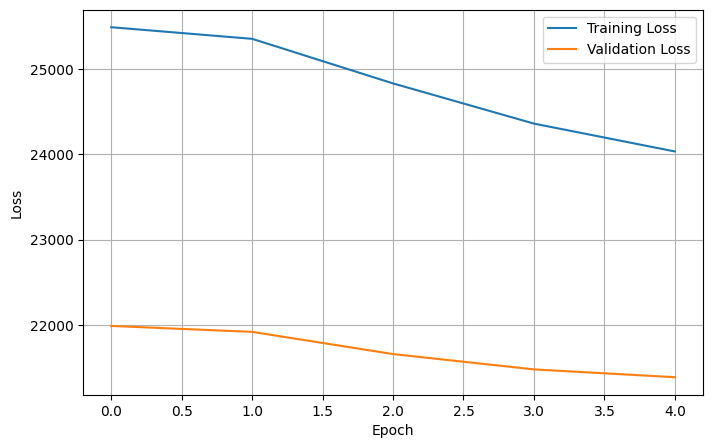

In [19]:
#visualizing the traning data
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
#Saving the trained Two-Tower model
os.makedirs("../Models", exist_ok=True)

user_model.save_weights("../Models/user_model.weights.h5")
movie_model.save_weights("../Models/movie_model.weights.h5")

print("User and movie model weights saved successfully.")

User and movie model weights saved successfully.


In [30]:
movie_ids = sorted(
    retrieval_interactions["movie_id"].unique().tolist()
)

print("Current vocabulary:", len(movie_ids))

Current vocabulary: 3533
